# 04 - Comparaison de quelques images


Comparer les signatures HSV et LBP de plusieurs images, puis classer les resultats. Cette experience porte sur un petit echantillon et ne constitue pas encore un index complet.

In [1]:
%pip install pillow numpy matplotlib scikit-image

  Using cached matplotlib-3.11.2-cp312-cp312-win_amd64.whl.metadata (80 kB)
  Using cached contourpy-1.4.0-cp312-cp312-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.68.0-cp312-cp312-win_amd64.whl.metadata (142 kB)
  Using cached kiwisolver-1.5.1-cp312-cp312-win_amd64.whl.metadata (5.2 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
  Using cached networkx-3.7-py3-none-any.whl.metadata (6.7 kB)
   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
    --------------------------------------- 0.3/12.6 MB ? eta -:--:--
    --------------------------------------- 0.3/12.6 MB ? eta -:--:--
   - -------------------------------------- 0.5/12.6 MB 882.6 kB/s eta 0:00:14
   --- ------------------------------------ 1.0/12.6 MB 1.1 MB/s eta 0:00:11
   ---- ----------------------------------- 1.3/12.6 MB 1.2 MB/s eta

In [2]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from skimage.feature import local_binary_pattern

base = Path("data/101_ObjectCategories")
if not base.is_dir():
    raise FileNotFoundError(f"Dossier introuvable : {base.resolve()}. Ouvre le notebook depuis la racine du projet.")

# Memes parametres que dans le notebook 03.
def signatures(chemin):
    with Image.open(chemin) as image:
        rgb = image.convert("RGB").resize((256, 256), Image.Resampling.LANCZOS)
    hsv = np.asarray(rgb.convert("HSV"))
    gris = np.asarray(rgb.convert("L"))
    couleur, _ = np.histogramdd(hsv.reshape(-1, 3), bins=(8, 8, 8),
                               range=((0, 256), (0, 256), (0, 256)))
    lbp = local_binary_pattern(gris, 8, 1, method="uniform")
    texture, _ = np.histogram(lbp, bins=np.arange(11))
    return (couleur / couleur.sum()).ravel(), texture / texture.sum()

# Distance de Hellinger, aussi appelee distance de Bhattacharyya dans OpenCV.
def distance_histogrammes(a, b):
    return np.sqrt(np.clip(1.0 - np.sqrt(a * b).sum(), 0.0, 1.0))

## Choisir une requete et un echantillon


On prend une image de requete et quelques images issues de plusieurs categories. Les chemins peuvent etre modifies pour explorer d autres exemples.

Requete : data\101_ObjectCategories\airplanes\image_0001.jpg | candidats : 11


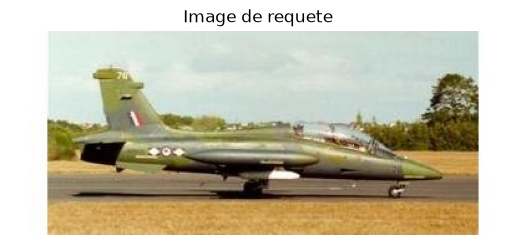

In [3]:
requete = base / "airplanes" / "image_0001.jpg"
categories = ["airplanes", "Motorbikes", "Faces", "watch"]
if not requete.is_file():
    raise FileNotFoundError(f"Requete introuvable : {requete}")
candidats = []
for categorie in categories:
    images = sorted((base / categorie).glob("*.jpg"))
    if len(images) < 3:
        raise ValueError(f"Moins de trois images dans la categorie : {categorie}")
    candidats.extend(chemin for chemin in images[:3] if chemin != requete)

couleur_requete, texture_requete = signatures(requete)
assert couleur_requete.shape == (512,) and texture_requete.shape == (10,)
assert np.isclose(couleur_requete.sum(), 1) and np.isclose(texture_requete.sum(), 1)
assert np.isclose(distance_histogrammes(couleur_requete, couleur_requete), 0, atol=1e-7)
assert np.isclose(distance_histogrammes(texture_requete, texture_requete), 0, atol=1e-7)
print("Requete :", requete, "| candidats :", len(candidats))
with Image.open(requete) as image:
    plt.imshow(image.convert("RGB"))
    plt.axis("off")
    plt.title("Image de requete")
    plt.show()

## Calculer les distances et classer


Les deux distances sont comprises entre 0 et 1 : plus elles sont petites, plus les histogrammes se ressemblent. Le score combine utilise des poids initiaux egaux ; ils restent a evaluer.

airplanes    image_0003.jpg   couleur=0.692 texture=0.046 combine=0.369
airplanes    image_0002.jpg   couleur=0.774 texture=0.054 combine=0.414
watch        image_0001.jpg   couleur=0.653 texture=0.180 combine=0.417
watch        image_0002.jpg   couleur=0.754 texture=0.118 combine=0.436
Faces        image_0003.jpg   couleur=0.735 texture=0.140 combine=0.438
watch        image_0003.jpg   couleur=0.701 texture=0.175 combine=0.438
Faces        image_0001.jpg   couleur=0.745 texture=0.134 combine=0.439
Faces        image_0002.jpg   couleur=0.763 texture=0.168 combine=0.465
Motorbikes   image_0003.jpg   couleur=0.712 texture=0.256 combine=0.484
Motorbikes   image_0001.jpg   couleur=0.800 texture=0.282 combine=0.541
Motorbikes   image_0002.jpg   couleur=0.799 texture=0.292 combine=0.545


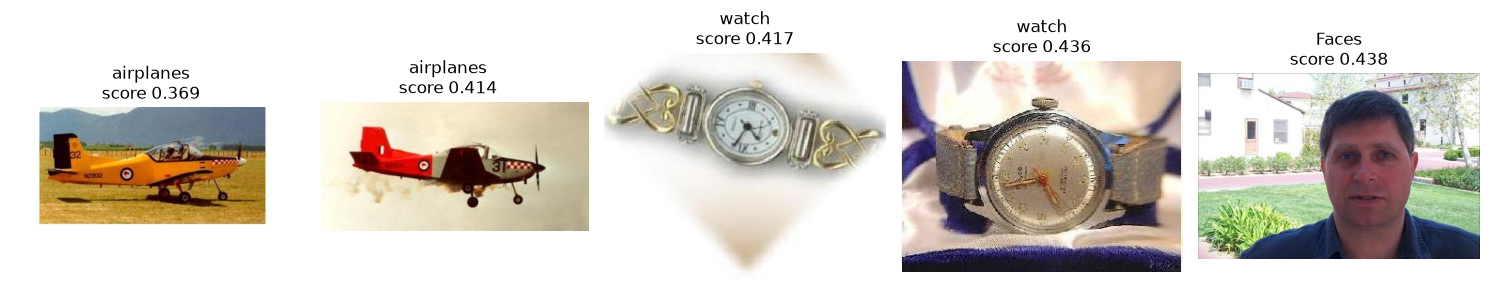

In [4]:
poids_couleur = 0.5
assert 0 <= poids_couleur <= 1
resultats = []
for chemin in candidats:
    couleur, texture = signatures(chemin)
    assert couleur.shape == couleur_requete.shape and texture.shape == texture_requete.shape
    assert np.isclose(couleur.sum(), 1) and np.isclose(texture.sum(), 1)
    d_couleur = distance_histogrammes(couleur_requete, couleur)
    d_texture = distance_histogrammes(texture_requete, texture)
    score = poids_couleur * d_couleur + (1 - poids_couleur) * d_texture
    resultats.append((score, d_couleur, d_texture, chemin))

resultats.sort(key=lambda resultat: resultat[0])
for score, d_couleur, d_texture, chemin in resultats:
    print(f"{chemin.parent.name:12} {chemin.name:16} couleur={d_couleur:.3f} texture={d_texture:.3f} combine={score:.3f}")

fig, axes = plt.subplots(1, min(5, len(resultats)), figsize=(15, 3))
for ax, (score, d_couleur, d_texture, chemin) in zip(np.atleast_1d(axes), resultats[:5]):
    with Image.open(chemin) as image:
        ax.imshow(image.convert("RGB"))
    ax.set_title(f"{chemin.parent.name}\nscore {score:.3f}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## Interpre­ter les resultats


Essaie plusieurs requetes et modifie poids_couleur entre 0 et 1 : 1 utilise seulement la couleur, 0 seulement la texture. Les categories ne garantissent pas une ressemblance visuelle ; le faible echantillon ne permet pas de conclure sur la performance. La comparaison euclidienne et le choix des poids restent a etudier.